# Лабораторная работа 1. Предсказание `RiskScore` линейной регрессией

Выполнил Демьянов Вячеслав, группа М8О-312БВ-24

Нужно предсказать `RiskScore` по данным о заёмщике. Основная метрика - MSE. Целевой порог `MSE < 18`. Из моделей разрешена только линейная регрессия, в том числе для отбора признаков

`sklearn` используется для сверки своих реализаций

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from sklearn.linear_model import LinearRegression as SkLinearRegression, SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

SEED = 42
THRESHOLD = 18.0
np.random.seed(SEED)
DATA = Path('data') if Path('data').exists() else Path('lab1/data')
OUT = DATA.parent
pd.set_option('display.width', 200, 'display.max_columns', 60)

## 1. Загрузка и первичная проверка данных

In [2]:
raw_train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
sample = pd.read_csv(DATA / 'ex.csv')
TARGET = 'RiskScore'

print('train:', raw_train.shape, '| test:', test.shape, '| пример посылки:', sample.shape)
assert TARGET in raw_train and TARGET not in test
assert set(raw_train.columns) - {TARGET} == set(test.columns) - {'ID'}, 'Набор признаков в train и test должен совпадать'
assert test['ID'].equals(sample['ID']), 'Порядок ID в test и ex.csv должен совпадать'

print('\nЧисло пропусков в строке -> сколько таких строк:')
print(raw_train.isna().sum(axis=1).value_counts().sort_index().to_string())
print('\nПропусков в test:', int(test.isna().sum().sum()))
print('Полных дубликатов в train:', int(raw_train.dropna(how='all').duplicated().sum()))

y_raw = raw_train[TARGET].dropna()
print('\nКвантили RiskScore в сыром train:')
print(y_raw.quantile([0, .005, .01, .02, .5, .98, .99, .995, 1]).to_string())
print('\nЗначения RiskScore с модулем больше 1000:')
print(y_raw[y_raw.abs() > 1000].value_counts().to_string())

train: (11017, 35) | test: (5000, 35) | пример посылки: (5000, 2)

Число пропусков в строке -> сколько таких строк:
0     9986
9      501
35     530

Пропусков в test: 0
Полных дубликатов в train: 487

Квантили RiskScore в сыром train:
0.000   -9.999999e+06
0.005   -9.999999e+06
0.010   -9.999999e+06
0.020    2.297356e+01
0.500    4.411876e+01
0.980    8.215545e+01
0.990    9.022040e+01
0.995    1.000000e+07
1.000    1.000000e+07

Значения RiskScore с модулем больше 1000:
RiskScore
-9999999.0     121
 10000000.0     94


In [3]:
def clean_train(df):
    '''удаляет пустые строки, дубликаты, значения-заглушки таргета и строки с пропусками'''
    log = {'исходно': len(df)}
    df = df.dropna(how='all'); log['без полностью пустых строк'] = len(df)
    df = df.drop_duplicates(); log['без дубликатов'] = len(df)
    df = df[df[TARGET].abs() < 1000]; log['без заглушек таргета ±1e7'] = len(df)
    df = df.dropna(); log['без строк с пропусками'] = len(df)
    return df.reset_index(drop=True), log

train, clean_log = clean_train(raw_train)
print(pd.Series(clean_log).to_string())

assert train.isna().sum().sum() == 0
assert not train.duplicated().any()
assert train[TARGET].between(0, 200).all()
assert train['ApplicationDate'].is_unique
print(f'\nПроверки пройдены. RiskScore после очистки: {train[TARGET].min():.2f} ... {train[TARGET].max():.2f}')

исходно                       11017
без полностью пустых строк    10487
без дубликатов                10000
без заглушек таргета ±1e7      9788
без строк с пропусками         9332

Проверки пройдены. RiskScore после очистки: 14.84 ... 97.60


Что сделано при очистке:

- 530 полностью пустых строк удалены, информации в них нет
- Дубликаты удалены, они завышали бы вес отдельных наблюдений и при кросс-валидации попадали бы одновременно в обучение и валидацию
- Значения `-9999999` и `10000000` это заглушки, на реальный риск они не похожи. Одна такая строка вносит порядка $10^{14}$ в сумму квадратов, поэтому они удалены
- Примерно у 450 строк одновременно отсутствуют 9 признаков, включая `CreditScore` и `BankruptcyHistory`. В тесте пропусков нет, поэтому модель обучается на полных строках

## 2. Разведочный анализ данных (EDA)

### 2.1. Целевая переменная

count    9332.00
mean       48.31
std        17.24
min        14.84
25%        32.69
50%        44.13
75%        65.06
max        97.60


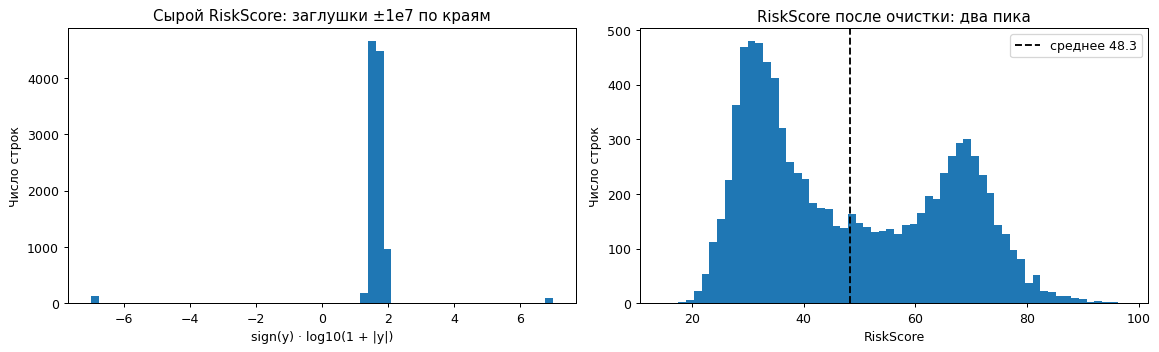

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sentinels = raw_train[TARGET].dropna()
ax[0].hist(np.sign(sentinels) * np.log10(1 + sentinels.abs()), bins=60)
ax[0].set(title='Сырой RiskScore: заглушки ±1e7 по краям', xlabel='sign(y) · log10(1 + |y|)', ylabel='Число строк')
ax[1].hist(train[TARGET], bins=60)
ax[1].axvline(train[TARGET].mean(), color='black', linestyle='--', linewidth=1.5, label=f'среднее {train[TARGET].mean():.1f}')
ax[1].set(title='RiskScore после очистки: два пика', xlabel='RiskScore', ylabel='Число строк')
ax[1].legend()
plt.tight_layout(); plt.show()
print(train[TARGET].describe().round(2).to_string())

### 2.2. Зависимости таргета от признаков и признаков друг от друга

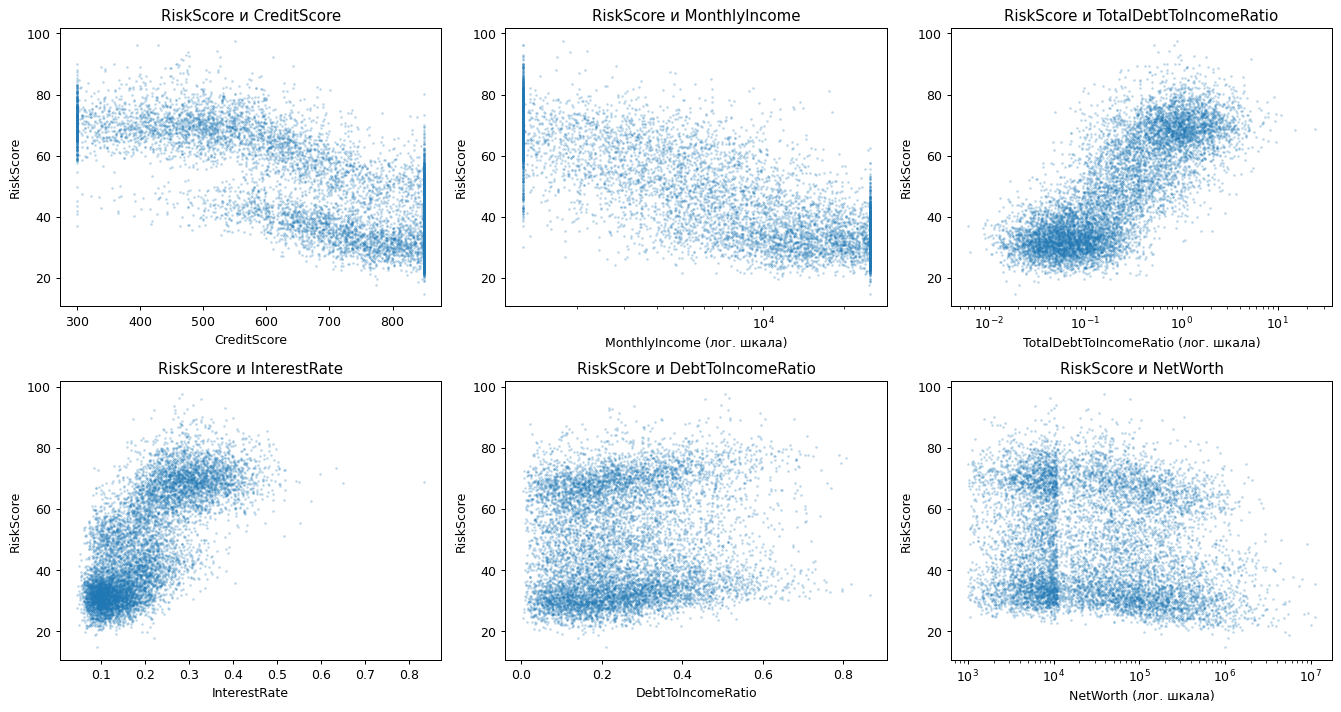

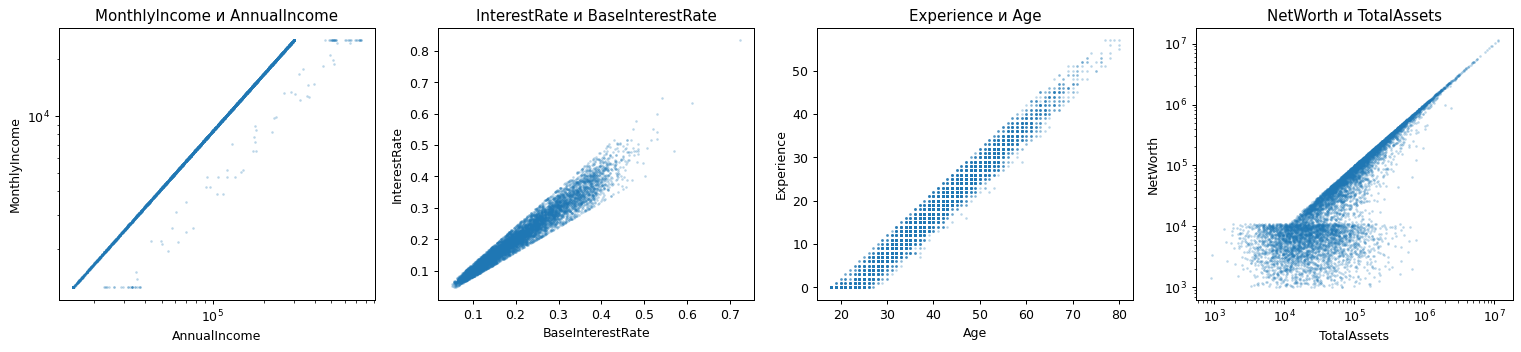

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
scatter_kw = dict(s=4, alpha=.3, linewidths=0)
for a, (col, log_x) in zip(ax.ravel(), [('CreditScore', False), ('MonthlyIncome', True), ('TotalDebtToIncomeRatio', True),
                                        ('InterestRate', False), ('DebtToIncomeRatio', False), ('NetWorth', True)]):
    a.scatter(train[col], train[TARGET], **scatter_kw)
    if log_x: a.set_xscale('log')
    a.set(title=f'RiskScore и {col}', xlabel=col + (' (лог. шкала)' if log_x else ''), ylabel='RiskScore')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, (u, v, lx) in zip(ax, [('AnnualIncome', 'MonthlyIncome', True), ('BaseInterestRate', 'InterestRate', False),
                              ('Age', 'Experience', False), ('TotalAssets', 'NetWorth', True)]):
    a.scatter(train[u], train[v], **scatter_kw)
    if lx: a.set_xscale('log'); a.set_yscale('log')
    a.set(title=f'{v} и {u}', xlabel=u, ylabel=v)
plt.tight_layout(); plt.show()

### 2.3. Матрица корреляций

Корреляция признаков с RiskScore (крайние значения):
CreditScore              -0.785
MonthlyIncome            -0.770
AnnualIncome             -0.758
TotalAssets              -0.147
NetWorth                 -0.146
LengthOfCreditHistory    -0.056
DebtToIncomeRatio         0.109
MonthlyLoanPayment        0.147
BankruptcyHistory         0.180
TotalDebtToIncomeRatio    0.554
InterestRate              0.744
BaseInterestRate          0.760

Сильнее всего связанные пары признаков:
TotalAssets       NetWorth              0.994
AnnualIncome      MonthlyIncome         0.984
Age               Experience            0.983
BaseInterestRate  InterestRate          0.975
CreditScore       BaseInterestRate     -0.933
                  InterestRate         -0.909
LoanAmount        MonthlyLoanPayment    0.868
CreditScore       MonthlyIncome         0.626


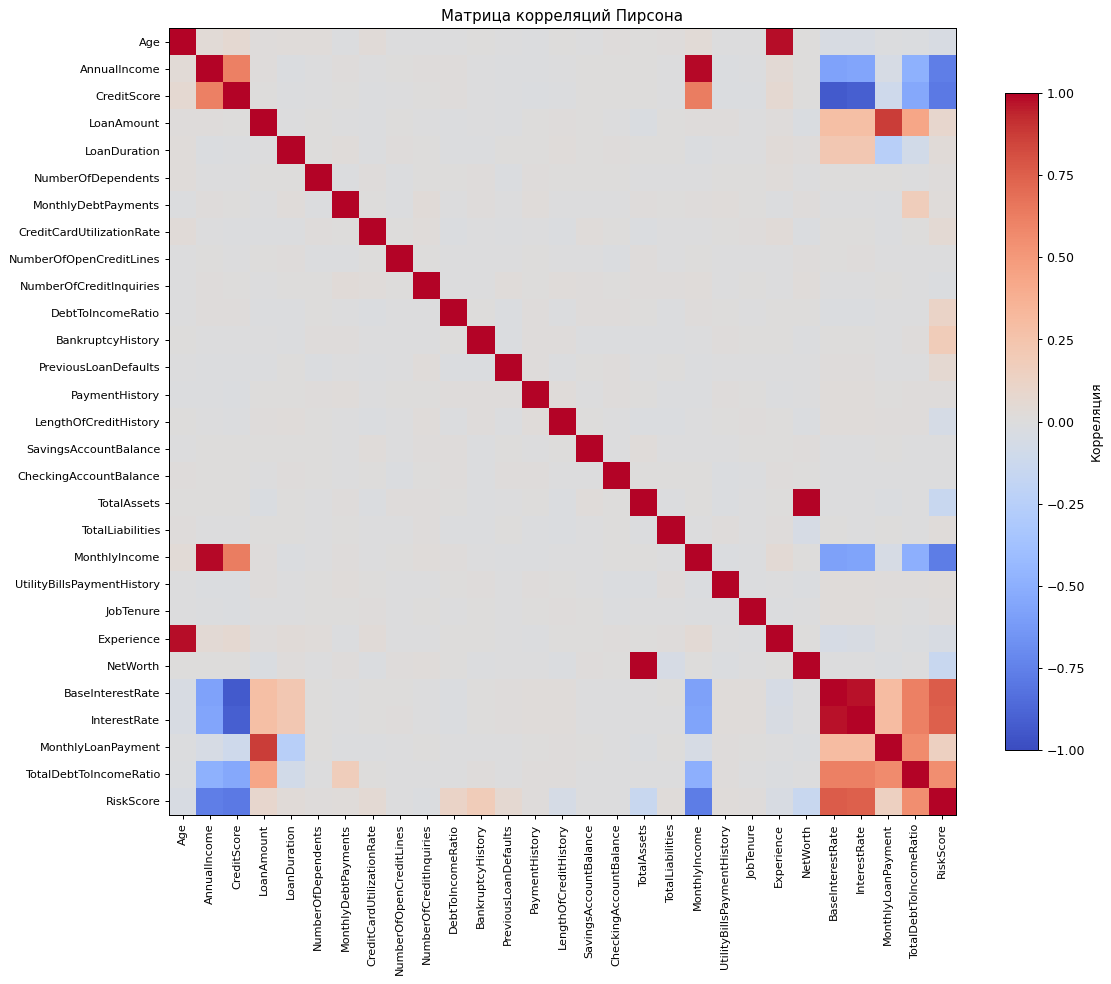

In [6]:
numeric = train.select_dtypes('number')
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
ax.set_title('Матрица корреляций Пирсона')
fig.colorbar(im, shrink=.8, label='Корреляция')
plt.tight_layout(); plt.show()

print('Корреляция признаков с RiskScore (крайние значения):')
target_corr = corr[TARGET].drop(TARGET).sort_values()
print(pd.concat([target_corr.head(6), target_corr.tail(6)]).round(3).to_string())

features_corr = corr.drop(index=TARGET, columns=TARGET)
pairs = features_corr.where(np.triu(np.ones(features_corr.shape, dtype=bool), 1)).stack()
print('\nСильнее всего связанные пары признаков:')
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

### 2.4. Категориальные признаки и связи между столбцами

Доля строк, где выполняется соотношение:
MonthlyLoanPayment = аннуитет(LoanAmount, InterestRate, LoanDuration)                  1.0000
TotalDebtToIncomeRatio = (MonthlyDebtPayments + MonthlyLoanPayment) / MonthlyIncome    1.0000
BaseInterestRate = 0.465 - 0.0005·CreditScore + 1e-6·LoanAmount + LoanDuration/1200    1.0000
InterestRate / BaseInterestRate в [0.8, 1.2]                                           1.0000
MonthlyIncome = AnnualIncome / 12                                                      0.9890
NetWorth = TotalAssets - TotalLiabilities                                              0.6881

Признаки, у которых значения в test выходят за диапазон train:
                            train_min   test_min     train_max     test_max
AnnualIncome                15000.000  15000.000  7.485080e+05   749283.000
CreditCardUtilizationRate       0.004      0.002  9.150000e-01        0.927
NumberOfOpenCreditLines         0.000      0.000  1.200000e+01       14.000
DebtToIncomeRatio          

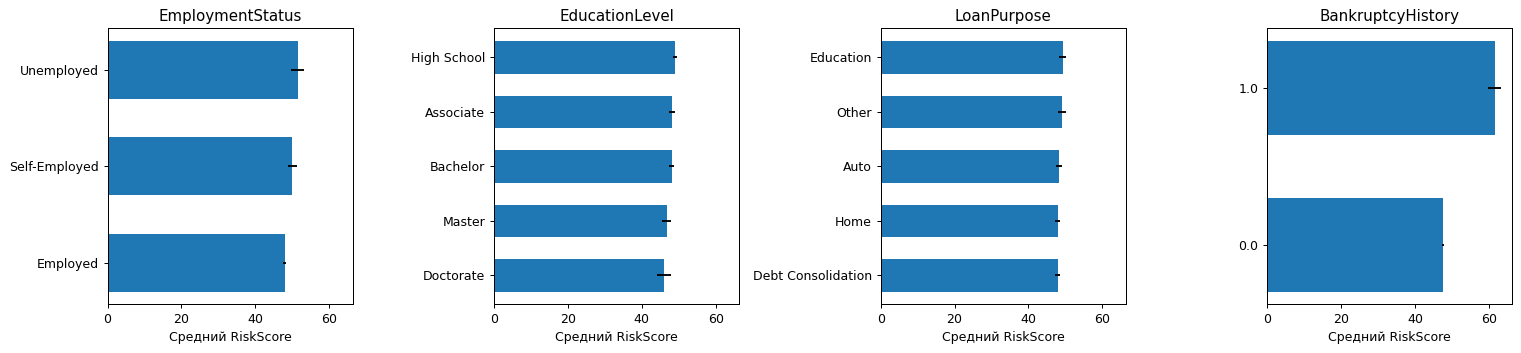

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4), sharex=True)
for a, col in zip(ax, ['EmploymentStatus', 'EducationLevel', 'LoanPurpose', 'BankruptcyHistory']):
    stats = train.groupby(col)[TARGET].agg(['mean', 'sem']).sort_values('mean')
    a.barh(stats.index.astype(str), stats['mean'], xerr=1.96 * stats['sem'], height=.6)
    a.set(title=col, xlabel='Средний RiskScore')
plt.tight_layout(); plt.show()

rate = train['InterestRate'] / 12
n_pay = train['LoanDuration']
annuity = train['LoanAmount'] * rate * (1 + rate) ** n_pay / ((1 + rate) ** n_pay - 1)
base_formula = 0.465 - 0.0005 * train['CreditScore'] + 1e-6 * train['LoanAmount'] + train['LoanDuration'] / 1200
checks = pd.Series({
    'MonthlyLoanPayment = аннуитет(LoanAmount, InterestRate, LoanDuration)': (annuity - train['MonthlyLoanPayment']).abs().lt(1e-6).mean(),
    'TotalDebtToIncomeRatio = (MonthlyDebtPayments + MonthlyLoanPayment) / MonthlyIncome': (((train['MonthlyDebtPayments'] + train['MonthlyLoanPayment']) / train['MonthlyIncome']) - train['TotalDebtToIncomeRatio']).abs().lt(1e-9).mean(),
    'BaseInterestRate = 0.465 - 0.0005·CreditScore + 1e-6·LoanAmount + LoanDuration/1200': (base_formula - train['BaseInterestRate']).abs().lt(1e-9).mean(),
    'InterestRate / BaseInterestRate в [0.8, 1.2]': (train['InterestRate'] / train['BaseInterestRate']).between(.8 - 1e-9, 1.2 + 1e-9).mean(),
    'MonthlyIncome = AnnualIncome / 12': (train['AnnualIncome'] / 12 - train['MonthlyIncome']).abs().lt(1).mean(),
    'NetWorth = TotalAssets - TotalLiabilities': (train['TotalAssets'] - train['TotalLiabilities'] - train['NetWorth']).abs().lt(1).mean(),
})
print('Доля строк, где выполняется соотношение:')
print(checks.round(4).to_string())

num_cols = [c for c in test.select_dtypes('number').columns if c != 'ID']
ranges = pd.DataFrame({'train_min': train[num_cols].min(), 'test_min': test[num_cols].min(),
                       'train_max': train[num_cols].max(), 'test_max': test[num_cols].max()})
print('\nПризнаки, у которых значения в test выходят за диапазон train:')
print(ranges[(ranges.test_max > ranges.train_max) | (ranges.test_min < ranges.train_min)].round(3).to_string())

Выводы EDA

1. Данные грязные. В train есть пустые строки, дубликаты, заглушки таргета ±1e7 и строки с пропусками. В test ничего этого нет, поэтому очистка нужна только для train
2. Таргет бимодальный, с пиками около 30 и 68. На графиках от `CreditScore` и `MonthlyIncome` видны две параллельные полосы с разрывом. Значит, есть скрытый бинарный фактор, которого нет среди признаков. Простая линейная модель вынужденно усредняет полосы и получает большую ошибку
3. Главные признаки это `CreditScore` (корреляция −0.79), `MonthlyIncome` (−0.77), `BaseInterestRate` и `InterestRate` (0.76 и 0.74), `TotalDebtToIncomeRatio` (0.55). Банкротство заметно повышает риск
4. Сильная мультиколлинеарность. `AnnualIncome` и `MonthlyIncome`, `Age` и `Experience`, `TotalAssets` и `NetWorth`, `InterestRate` и `BaseInterestRate` почти дублируют друг друга. Коэффициенты модели на всех столбцах неустойчивы, поэтому нужны отбор признаков и L2-регуляризация
5. Распределения с тяжёлым хвостом и насыщением. Доходы, активы и долги лучше брать в логарифме, а `CreditScore` и доход упираются в границы 300, 850, 1250 и 25000
6. Часть столбцов вычисляется из других. `MonthlyLoanPayment`, `TotalDebtToIncomeRatio` и `BaseInterestRate` восстанавливаются формулами точно. `InterestRate` равен `BaseInterestRate`, умноженному на случайный множитель из отрезка [0.8, 1.2]
7. В test встречаются значения шире диапазона train. Сплайны опасно экстраполировать, поэтому непрерывные признаки обрезаются по границам train

## 3. Нормализация

$$z = \frac{x-\mu}{\sigma}, \qquad x_{\text{minmax}} = \frac{x-x_{\min}}{x_{\max}-x_{\min}}$$

Параметры считаются только на обучающей части и затем применяются к валидации и тесту, чтобы не было утечки

In [8]:
class ZScoreScaler:
    '''приводит каждый признак к нулевому среднему и единичному стандартному отклонению'''
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1.0
        return self
    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.scale_
    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.scale_ + self.mean_
    def fit_transform(self, X):
        return self.fit(X).transform(X)


class MinMaxNormalizer:
    '''приводит каждый признак к отрезку [0, 1] по минимуму и максимуму обучающей выборки'''
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        self.range_ = X.max(axis=0) - self.min_
        self.range_[self.range_ == 0] = 1.0
        return self
    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.range_
    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.range_ + self.min_
    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [9]:
X_check = train[num_cols].to_numpy()
z_mine = ZScoreScaler().fit_transform(X_check)
m_mine = MinMaxNormalizer().fit_transform(X_check)

assert np.allclose(z_mine.mean(0), 0) and np.allclose(z_mine.std(0), 1)
assert np.isclose(m_mine.min(), 0) and np.isclose(m_mine.max(), 1)
assert np.allclose(ZScoreScaler().fit(X_check).inverse_transform(z_mine), X_check)
assert np.allclose(MinMaxNormalizer().fit(X_check).inverse_transform(m_mine), X_check)
print('Проверки нормализации пройдены')

Проверки нормализации пройдены


## 4. Метрики

$$\mathrm{MSE}=\frac1n\sum(y_i-\hat y_i)^2,\quad \mathrm{MAE}=\frac1n\sum|y_i-\hat y_i|,\quad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2},\quad \mathrm{MAPE}=\frac1n\sum\frac{|y_i-\hat y_i|}{|y_i|}$$

In [10]:
def mse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return np.mean((y_true - y_pred) ** 2)

def mae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return np.mean(np.abs(y_true - y_pred))

def r2(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    if ss_tot == 0:
        return 1.0 if ss_res == 0 else 0.0
    return 1 - ss_res / ss_tot

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return np.mean(np.abs(y_true - y_pred) / np.maximum(np.abs(y_true), np.finfo(float).eps))

METRICS = {'MSE': mse, 'MAE': mae, 'R2': r2, 'MAPE': mape}
SK_METRICS = {'MSE': mean_squared_error, 'MAE': mean_absolute_error, 'R2': r2_score, 'MAPE': mean_absolute_percentage_error}

def all_metrics(y_true, y_pred):
    return {name: fn(y_true, y_pred) for name, fn in METRICS.items()}

y_t, y_p = np.array([1., 2., 4.]), np.array([2., 2., 2.])
assert np.isclose(mse(y_t, y_p), 5 / 3)
assert np.isclose(mae(y_t, y_p), 1.0)
assert np.isclose(r2(y_t, y_p), 1 - 5 / (14 / 3))
assert np.isclose(mape(y_t, y_p), (1 + 0 + .5) / 3)

rng = np.random.default_rng(SEED)
y_rand = rng.normal(50, 15, 1000)
cases = {'случайный шум': (y_rand, y_rand + rng.normal(0, 5, 1000)),
         'идеальный прогноз': (y_rand, y_rand.copy()),
         'прогноз средним': (y_rand, np.full(1000, y_rand.mean())),
         'константный таргет': (np.ones(10), np.ones(10) * 2),
         'ноль в таргете': (np.array([0., 1., 2.]), np.array([.5, 1., 2.]))}
rows = []
for name, (t, p) in cases.items():
    for m in METRICS:
        mine, sk = METRICS[m](t, p), SK_METRICS[m](t, p)
        assert np.isclose(mine, sk), f'{m} расходится со sklearn: {name}'
        rows.append({'случай': name, 'метрика': m, 'своя': mine, 'sklearn': sk})
print(pd.DataFrame(rows).pivot(index='случай', columns='метрика', values='своя').round(4).to_string())
print('\nВсе значения совпали со sklearn')

метрика                 MAE          MAPE       MSE      R2
случай                                                     
идеальный прогноз    0.0000  0.000000e+00    0.0000  1.0000
константный таргет   1.0000  1.000000e+00    1.0000  0.0000
ноль в таргете       0.1667  7.505999e+14    0.0833  0.8750
прогноз средним     11.7347  3.196000e-01  219.9537  0.0000
случайный шум        4.0371  9.410000e-02   25.8722  0.8824

Все значения совпали со sklearn


## 5. Класс линейной регрессии

Минимизируется функция

$$J(w, b) = \frac1n\lVert y - Xw - b\rVert^2 + R(w),$$

где $R(w)$ равно $0$, $\lambda\lVert w\rVert_1$, $\lambda\lVert w\rVert_2^2$, $\lambda(\rho\lVert w\rVert_1 + (1-\rho)\lVert w\rVert_2^2)$ или $\lambda\sum_j |w_j|^p$. Свободный член не штрафуется. Перед обучением $X$ и $y$ центрируются

Способы обучения:

- `analytic`. Нормальное уравнение $w = (X^\top X + n\lambda I)^{-1}X^\top y$. Доступно без штрафа и для L2
- `gd`. Полный градиентный спуск. Шаг по умолчанию равен $1/L$, где $L$ это константа Липшица градиента. Если функция выросла, шаг уменьшается вдвое. L1-часть учитывается проксимальным шагом (мягким порогом), поэтому точные нули возможны
- `sgd`. Мини-батчи, затухающий шаг и усреднение весов по второй половине эпох, которое снижает шум итоговой оценки

Для $p<2$ функция $|w|^p$ негладкая в нуле, поэтому используется сглаживание $(w^2+\varepsilon)^{p/2}$. При $p<1$ задача невыпуклая, и спуск находит только локальный минимум

In [11]:
class LinearRegression:
    '''линейная регрессия с методами analytic, gd, sgd и штрафами None, l1, l2, elasticnet, lp'''

    def __init__(self, method='analytic', penalty=None, lam=0.0, l1_ratio=0.5, p=2.0, lr=None,
                 n_iter=5000, batch_size=64, tol=1e-12, fit_intercept=True, random_state=SEED, eps=1e-8):
        if method not in ('analytic', 'gd', 'sgd'):
            raise ValueError(f'Неизвестный метод: {method}')
        if penalty not in (None, 'l1', 'l2', 'elasticnet', 'lp'):
            raise ValueError(f'Неизвестный штраф: {penalty}')
        if method == 'analytic' and penalty not in (None, 'l2'):
            raise ValueError('Аналитическое решение есть только без штрафа и для L2')
        if lam < 0 or p <= 0:
            raise ValueError('Нужно lam >= 0 и p > 0')
        self.method, self.penalty, self.lam, self.l1_ratio, self.p = method, penalty, lam, l1_ratio, p
        self.lr, self.n_iter, self.batch_size, self.tol = lr, n_iter, batch_size, tol
        self.fit_intercept, self.random_state, self.eps = fit_intercept, random_state, eps

    def _l1_strength(self):
        return {'l1': self.lam, 'elasticnet': self.lam * self.l1_ratio}.get(self.penalty, 0.0)

    def _penalty_value(self, w):
        if self.penalty is None: return 0.0
        if self.penalty == 'l1': return self.lam * np.abs(w).sum()
        if self.penalty == 'l2': return self.lam * (w ** 2).sum()
        if self.penalty == 'elasticnet':
            return self.lam * (self.l1_ratio * np.abs(w).sum() + (1 - self.l1_ratio) * (w ** 2).sum())
        if self.p >= 2: return self.lam * (np.abs(w) ** self.p).sum()
        return self.lam * ((w ** 2 + self.eps) ** (self.p / 2)).sum()

    def _penalty_grad(self, w):
        '''градиент гладкой части штрафа. L1-часть учитывается проксимальным шагом'''
        if self.penalty == 'l2': return 2 * self.lam * w
        if self.penalty == 'elasticnet': return 2 * self.lam * (1 - self.l1_ratio) * w
        if self.penalty == 'lp':
            if self.p >= 2: return self.lam * self.p * np.sign(w) * np.abs(w) ** (self.p - 1)
            return self.lam * self.p * w * (w ** 2 + self.eps) ** (self.p / 2 - 1)
        return np.zeros_like(w)

    def _prox(self, w, step):
        t = step * self._l1_strength()
        return np.sign(w) * np.maximum(np.abs(w) - t, 0.0) if t > 0 else w

    def _objective(self, X, y, w):
        return np.mean((y - X @ w) ** 2) + self._penalty_value(w)

    def _fit_analytic(self, X, y):
        n, m = X.shape
        A = X.T @ X
        if self.penalty == 'l2':
            A = A + n * self.lam * np.eye(m)
        try:
            return np.linalg.solve(A, X.T @ y)
        except np.linalg.LinAlgError:
            return np.linalg.pinv(A) @ (X.T @ y)

    def _fit_gd(self, X, y):
        n, m = X.shape
        w = np.zeros(m)
        step = self.lr if self.lr else 1.0 / (2 * np.linalg.norm(X, 2) ** 2 / n + 2 * self.lam * (self.penalty in ('l2', 'elasticnet')))
        J = self._objective(X, y, w)
        history = [J]
        for it in range(self.n_iter):
            grad = 2 / n * X.T @ (X @ w - y) + self._penalty_grad(w)
            while True:
                w_new = self._prox(w - step * grad, step)
                J_new = self._objective(X, y, w_new)
                if J_new <= J or step < 1e-14:
                    break
                step /= 2
            w, delta = w_new, J - J_new
            J = J_new
            history.append(J)
            if abs(delta) <= self.tol * max(abs(J), 1.0):
                break
        self.history_, self.n_iter_ = history, it + 1
        return w

    def _fit_sgd(self, X, y):
        n, m = X.shape
        rng = np.random.default_rng(self.random_state)
        w, w_avg, n_avg = np.zeros(m), np.zeros(m), 0
        bs = min(self.batch_size, n)
        L = 2 * (np.linalg.norm(X, 2) ** 2 / n + (X ** 2).sum(axis=1).mean() / bs)
        lr0 = self.lr if self.lr else 1.0 / L
        history = [self._objective(X, y, w)]
        for epoch in range(self.n_iter):
            step = lr0 / (1 + 10 * epoch / max(self.n_iter, 1))
            perm = rng.permutation(n)
            for start in range(0, n, bs):
                idx = perm[start:start + bs]
                grad = 2 / len(idx) * X[idx].T @ (X[idx] @ w - y[idx]) + self._penalty_grad(w)
                current = step
                if self.penalty == 'lp' and self.p > 2:
                    curvature = self.lam * self.p * (self.p - 1) * np.abs(w).max() ** (self.p - 2)
                    current = min(step, 1.0 / (L + curvature))
                w = self._prox(w - current * grad, current)
                if epoch >= self.n_iter // 2:
                    n_avg += 1
                    w_avg += (w - w_avg) / n_avg
            history.append(self._objective(X, y, w))
        if not np.isfinite(w).all():
            raise FloatingPointError('SGD разошёлся: уменьшите lr')
        self.history_, self.n_iter_ = history, self.n_iter
        return w_avg if n_avg else w

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float).ravel()
        if X.ndim != 2 or len(X) != len(y):
            raise ValueError('Ожидается X формы (n, m) и y длины n')
        x_mean = X.mean(axis=0) if self.fit_intercept else np.zeros(X.shape[1])
        y_mean = y.mean() if self.fit_intercept else 0.0
        Xc, yc = X - x_mean, y - y_mean
        solver = {'analytic': self._fit_analytic, 'gd': self._fit_gd, 'sgd': self._fit_sgd}[self.method]
        self.coef_ = solver(Xc, yc)
        self.intercept_ = y_mean - x_mean @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

### Сравнение реализаций со sklearn

Для сравнения берётся подвыборка признаков без дублирующих столбцов. На почти коллинеарных данных градиентный спуск сходится слишком медленно. Выборка делится на обучающую и отложенную части 80/20

In [12]:
GD_NUMERIC = ['Age', 'MonthlyIncome', 'CreditScore', 'LoanAmount', 'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments',
              'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio',
              'BankruptcyHistory', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance',
              'CheckingAccountBalance', 'NetWorth', 'TotalLiabilities', 'UtilityBillsPaymentHistory', 'JobTenure',
              'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio']
CATEGORICAL = ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']
CATEGORIES = {col: sorted(train[col].unique()) for col in CATEGORICAL}

def one_hot(df):
    '''one-hot кодирование с отбрасыванием первой категории, чтобы не было точной коллинеарности'''
    return pd.DataFrame({f'{col}={v}': (df[col] == v).astype(float) for col in CATEGORICAL for v in CATEGORIES[col][1:]}, index=df.index)

def simple_design(df):
    return pd.concat([df[GD_NUMERIC].astype(float), one_hot(df)], axis=1)

def split_indices(n, test_size=.2, seed=SEED):
    perm = np.random.default_rng(seed).permutation(n)
    n_val = int(n * test_size)
    return perm[n_val:], perm[:n_val]

X_simple = simple_design(train).to_numpy()
y_all = train[TARGET].to_numpy()
tr_idx, val_idx = split_indices(len(y_all))
assert len(set(tr_idx) & set(val_idx)) == 0 and len(tr_idx) + len(val_idx) == len(y_all)

scaler = ZScoreScaler().fit(X_simple[tr_idx])
Xz_tr, Xz_val = scaler.transform(X_simple[tr_idx]), scaler.transform(X_simple[val_idx])
y_tr, y_val = y_all[tr_idx], y_all[val_idx]
print('Форма X:', Xz_tr.shape, '| число обусловленности:', round(np.linalg.cond(Xz_tr), 1))

models = {
    'Своя: analytic': LinearRegression(method='analytic'),
    'Своя: GD': LinearRegression(method='gd', n_iter=30000, tol=1e-13),
    'Своя: SGD': LinearRegression(method='sgd', n_iter=300, batch_size=64),
    'sklearn: LinearRegression': SkLinearRegression(),
    'sklearn: SGDRegressor': SGDRegressor(penalty=None, max_iter=300, tol=None, learning_rate='invscaling', eta0=.01,
                                          average=True, random_state=SEED),
}
rows, fitted = [], {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(Xz_tr, y_tr)
    seconds = time.perf_counter() - start
    fitted[name] = model
    rows.append({'модель': name, **all_metrics(y_val, model.predict(Xz_val)), 'время, с': seconds})
reference = fitted['Своя: analytic'].coef_
comparison = pd.DataFrame(rows).set_index('модель')
comparison['макс. |w - w_analytic|'] = [np.abs(np.ravel(fitted[n].coef_) - reference).max() for n in comparison.index]
print(comparison.round(4).to_string())

sk_ols = fitted['sklearn: LinearRegression']
assert np.allclose(reference, sk_ols.coef_, atol=1e-8), 'Аналитика расходится со sklearn'
assert np.isclose(fitted['Своя: analytic'].intercept_, sk_ols.intercept_)
assert abs(comparison.loc['Своя: GD', 'MSE'] - comparison.loc['Своя: analytic', 'MSE']) < 1e-3, 'GD не сошёлся к аналитике'
assert abs(comparison.loc['Своя: SGD', 'MSE'] - comparison.loc['Своя: analytic', 'MSE']) < .5, 'SGD не сошёлся к аналитике'
for bad in [dict(method='analytic', penalty='l1'), dict(method='x'), dict(penalty='x'), dict(lam=-1.)]:
    try:
        LinearRegression(**bad)
    except ValueError:
        continue
    raise AssertionError(f'Некорректные параметры не отклонены: {bad}')

rng = np.random.default_rng(SEED)
X_syn = rng.normal(size=(3000, 5))
w_true, b_true = np.array([1.5, -2., 0., 3., .5]), 7.
y_syn = X_syn @ w_true + b_true + rng.normal(0, .01, 3000)
for method in ('analytic', 'gd', 'sgd'):
    synthetic = LinearRegression(method=method, n_iter=2000 if method == 'gd' else 100).fit(X_syn, y_syn)
    assert np.allclose(synthetic.coef_, w_true, atol=.01) and abs(synthetic.intercept_ - b_true) < .01, method
print('\nПроверки пройдены: аналитика совпала со sklearn, GD и SGD сошлись к тому же решению, истинные веса синтетики восстановлены')

Форма X: (7466, 40) | число обусловленности: 11.5
                               MSE     MAE      R2    MAPE  время, с  макс. |w - w_analytic|
модель                                                                                      
Своя: analytic             51.0628  5.7228  0.8268  0.1361    0.0032                  0.0000
Своя: GD                   51.0628  5.7228  0.8268  0.1361    2.7638                  0.0001
Своя: SGD                  51.0467  5.7247  0.8268  0.1361    1.5503                  0.0337
sklearn: LinearRegression  51.0628  5.7228  0.8268  0.1361    0.0141                  0.0000
sklearn: SGDRegressor      51.0411  5.7250  0.8268  0.1361    0.6472                  0.0395

Проверки пройдены: аналитика совпала со sklearn, GD и SGD сошлись к тому же решению, истинные веса синтетики восстановлены


z-score            cond(X) =           11.5 | MSE после 3000 итераций = 50.047
min-max            cond(X) =           43.0 | MSE после 3000 итераций = 50.051
без нормализации   cond(X) =   21,527,011.6 | MSE после 3000 итераций = 126.508


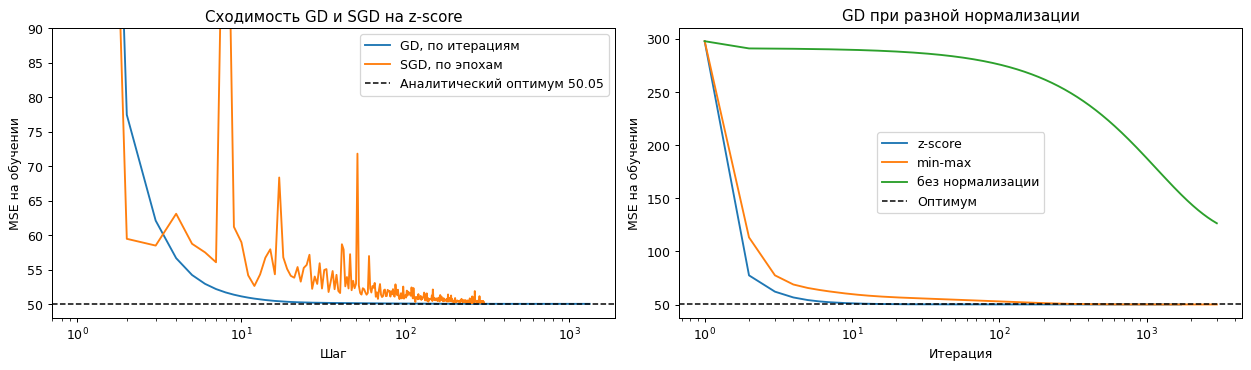

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
gd_hist, sgd_hist = fitted['Своя: GD'].history_, fitted['Своя: SGD'].history_
opt = np.mean((y_tr - y_tr.mean() - (Xz_tr - Xz_tr.mean(0)) @ reference) ** 2)
ax[0].plot(np.arange(1, len(gd_hist) + 1), gd_hist, label='GD, по итерациям')
ax[0].plot(np.arange(1, len(sgd_hist) + 1), sgd_hist, label='SGD, по эпохам')
ax[0].axhline(opt, color='black', linestyle='--', linewidth=1.2, label=f'Аналитический оптимум {opt:.2f}')
ax[0].set(xscale='log', ylim=(opt - 2, opt + 40), title='Сходимость GD и SGD на z-score', xlabel='Шаг', ylabel='MSE на обучении')
ax[0].legend()

histories = {}
for name, X_variant in {'z-score': Xz_tr, 'min-max': MinMaxNormalizer().fit_transform(X_simple[tr_idx]), 'без нормализации': X_simple[tr_idx]}.items():
    run = LinearRegression(method='gd', n_iter=3000, tol=0).fit(X_variant, y_tr)
    histories[name] = run.history_
    print(f'{name:18s} cond(X) = {np.linalg.cond(X_variant - X_variant.mean(0)):>14,.1f} | MSE после 3000 итераций = {run.history_[-1]:.3f}')
for name, hist in histories.items():
    ax[1].plot(np.arange(1, len(hist) + 1), hist, label=name)
ax[1].axhline(opt, color='black', linestyle='--', linewidth=1.2, label='Оптимум')
ax[1].set(xscale='log', title='GD при разной нормализации', xlabel='Итерация', ylabel='MSE на обучении')
ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Кросс-валидация k-fold и leave-one-out

Оба разбиения написаны как генераторы пар индексов `(train, val)`. Нормализация обучается внутри каждого фолда, поэтому информация из валидации в обучение не попадает

In [14]:
def kfold_splits(n, k=5, shuffle=True, seed=SEED):
    '''разбивает n объектов на k непересекающихся фолдов почти равного размера'''
    if not 2 <= k <= n:
        raise ValueError('Нужно 2 <= k <= n')
    order = np.random.default_rng(seed).permutation(n) if shuffle else np.arange(n)
    for fold in np.array_split(order, k):
        yield np.setdiff1d(order, fold), fold

def leave_one_out_splits(n):
    '''на каждом шаге в валидации один объект, в обучении все остальные'''
    for i in range(n):
        yield np.delete(np.arange(n), i), np.array([i])

def cross_validate(make_model, X, y, splits):
    '''возвращает прогнозы вне обучения (out-of-fold) и MSE по каждому фолду'''
    X, y = np.asarray(X, float), np.asarray(y, float)
    oof, fold_mse = np.full(len(y), np.nan), []
    for tr, val in splits:
        scaler = ZScoreScaler()
        oof[val] = make_model().fit(scaler.fit_transform(X[tr]), y[tr]).predict(scaler.transform(X[val]))
        fold_mse.append(mse(y[val], oof[val]))
    return oof, np.array(fold_mse)

In [15]:
make_ols = lambda: LinearRegression(method='analytic')

n_demo = 103
folds = list(kfold_splits(n_demo, 5))
assert len(folds) == 5
assert sorted(np.concatenate([val for _, val in folds]).tolist()) == list(range(n_demo)), 'Каждый объект должен быть в валидации ровно один раз'
assert all(len(set(tr) & set(val)) == 0 and len(tr) + len(val) == n_demo for tr, val in folds), 'Train и val не должны пересекаться'
loo = list(leave_one_out_splits(n_demo))
assert len(loo) == n_demo and all(len(v) == 1 and v[0] not in tr for tr, v in loo)

kf_oof, kf_folds = cross_validate(make_ols, X_simple, y_all, kfold_splits(len(y_all), 5))
print(f'Вся выборка, 5-fold: MSE = {mse(y_all, kf_oof):.3f} (разброс по фолдам ±{kf_folds.std():.3f})')

n_sub = 400
X_sub, y_sub = X_simple[:n_sub], y_all[:n_sub]
loo_oof, _ = cross_validate(make_ols, X_sub, y_sub, leave_one_out_splits(n_sub))
kf_sub, _ = cross_validate(make_ols, X_sub, y_sub, kfold_splits(n_sub, 5))
print(f'{n_sub} строк: LOO MSE = {mse(y_sub, loo_oof):.3f}, 5-fold MSE = {mse(y_sub, kf_sub):.3f}')

Вся выборка, 5-fold: MSE = 50.652 (разброс по фолдам ±2.510)
400 строк: LOO MSE = 51.838, 5-fold MSE = 53.600


LOO почти несмещён, но требует $n$ обучений, поэтому здесь он считается на 400 строках. Дальше для сравнения моделей используется более быстрый k-fold

## 7. Регуляризация L1, L2, L1+L2 и Lp

Сначала проверяется, что штрафы написаны верно. Целевые функции sklearn записаны иначе, поэтому параметры нужно пересчитать:

| Штраф | Свой параметр | Параметр sklearn |
|---|---|---|
| L2 | $\lambda$ | `Ridge(alpha = n·λ)` |
| L1 | $\lambda$ | `Lasso(alpha = λ/2)` |
| L1+L2 | $\lambda_1 = \lambda\rho$, $\lambda_2 = \lambda(1-\rho)$ | `ElasticNet`, $\alpha\rho_s = \lambda_1/2$, $\alpha(1-\rho_s) = \lambda_2$ |

Для Lp в sklearn готового аналога нет, поэтому решение сверяется с численной минимизацией той же функции через `scipy.optimize`

In [16]:
def compare_coefs(name, mine, sk):
    gap = np.abs(mine.coef_ - sk.coef_).max()
    print(f'{name:34s} макс. |w_своя - w_sklearn| = {gap:.2e} | MSE на отложенной: своя {mse(y_val, mine.predict(Xz_val)):.4f}, sklearn {mse(y_val, sk.predict(Xz_val)):.4f} | нулевых весов {int((np.abs(mine.coef_) < 1e-8).sum())}')
    return gap

n_tr = len(y_tr)
gd_kw = dict(method='gd', n_iter=30000, tol=1e-14)

lam = .1
ridge_gap = compare_coefs('L2, analytic против Ridge', LinearRegression(method='analytic', penalty='l2', lam=lam).fit(Xz_tr, y_tr), Ridge(alpha=n_tr * lam).fit(Xz_tr, y_tr))
ridge_gd_gap = compare_coefs('L2, GD против Ridge', LinearRegression(penalty='l2', lam=lam, **gd_kw).fit(Xz_tr, y_tr), Ridge(alpha=n_tr * lam).fit(Xz_tr, y_tr))

lam = .5
lasso_gap = compare_coefs('L1, GD против Lasso', LinearRegression(penalty='l1', lam=lam, **gd_kw).fit(Xz_tr, y_tr), Lasso(alpha=lam / 2, tol=1e-9, max_iter=200000).fit(Xz_tr, y_tr))

lam1, lam2 = .3, .1
alpha_en = lam1 / 2 + lam2
rho_en = (lam1 / 2) / alpha_en
en_gap = compare_coefs('L1+L2, GD против ElasticNet', LinearRegression(penalty='elasticnet', lam=lam1 + lam2, l1_ratio=lam1 / (lam1 + lam2), **gd_kw).fit(Xz_tr, y_tr),
                       ElasticNet(alpha=alpha_en, l1_ratio=rho_en, tol=1e-9, max_iter=200000).fit(Xz_tr, y_tr))

assert ridge_gap < 1e-8 and ridge_gd_gap < 1e-2 and lasso_gap < 1e-2 and en_gap < 1e-2, 'Регуляризация расходится со sklearn'

sgd_l2 = LinearRegression(method='sgd', penalty='l2', lam=.1, n_iter=200).fit(Xz_tr, y_tr)
sgd_l1 = LinearRegression(method='sgd', penalty='l1', lam=.5, n_iter=200).fit(Xz_tr, y_tr)
print(f'\nSGD с L2: MSE {mse(y_val, sgd_l2.predict(Xz_val)):.4f} | SGD с L1: MSE {mse(y_val, sgd_l1.predict(Xz_val)):.4f}')
print('Проверки L1, L2 и L1+L2 пройдены')

L2, analytic против Ridge          макс. |w_своя - w_sklearn| = 1.91e-14 | MSE на отложенной: своя 51.4038, sklearn 51.4038 | нулевых весов 0
L2, GD против Ridge                макс. |w_своя - w_sklearn| = 5.40e-06 | MSE на отложенной: своя 51.4038, sklearn 51.4038 | нулевых весов 0
L1, GD против Lasso                макс. |w_своя - w_sklearn| = 1.52e-05 | MSE на отложенной: своя 51.0286, sklearn 51.0286 | нулевых весов 25
L1+L2, GD против ElasticNet        макс. |w_своя - w_sklearn| = 4.85e-06 | MSE на отложенной: своя 51.7190, sklearn 51.7190 | нулевых весов 21

SGD с L2: MSE 51.3957 | SGD с L1: MSE 51.0322
Проверки L1, L2 и L1+L2 пройдены


In [17]:
def lp_objective(w, X, y, lam, p, eps=1e-8):
    penalty = (np.abs(w) ** p).sum() if p >= 2 else ((w ** 2 + eps) ** (p / 2)).sum()
    return np.mean((y - X @ w) ** 2) + lam * penalty

X_lp = Xz_tr[:, :10]
X_lpc, y_lpc = X_lp - X_lp.mean(0), y_tr - y_tr.mean()
rows = []
for p_value in (1.5, 2.0, 3.0, 4.0):
    ours = LinearRegression(penalty='lp', p=p_value, lam=.5, method='gd', n_iter=50000, tol=1e-15).fit(X_lp, y_tr)
    numeric = minimize(lp_objective, np.zeros(10), args=(X_lpc, y_lpc, .5, p_value), method='L-BFGS-B',
                       options=dict(maxiter=20000, ftol=1e-14, gtol=1e-9)).x
    gap = np.abs(ours.coef_ - numeric).max()
    rows.append({'p': p_value, 'J своя': lp_objective(ours.coef_, X_lpc, y_lpc, .5, p_value), 'J scipy': lp_objective(numeric, X_lpc, y_lpc, .5, p_value), 'макс. |Δw|': gap, 'Σ|w|': np.abs(ours.coef_).sum()})
    assert gap < 1e-2, f'Lp при p={p_value} расходится с численной минимизацией'
print(pd.DataFrame(rows).round(5).to_string(index=False))

lp2 = LinearRegression(penalty='lp', p=2, lam=.5, method='gd', n_iter=50000, tol=1e-15).fit(X_lp, y_tr)
l2 = LinearRegression(penalty='l2', lam=.5, method='analytic').fit(X_lp, y_tr)
assert np.allclose(lp2.coef_, l2.coef_, atol=1e-3), 'Lp при p=2 должен совпадать с L2'

print('Проверки Lp пройдены')

  p    J своя   J scipy  макс. |Δw|     Σ|w|
1.5  97.32947  97.32947         0.0 17.33125
2.0 126.91972 126.91972         0.0 14.92330
3.0 190.04417 190.04417         0.0  9.35679
4.0 216.52207 216.52207         0.0  7.35092
Проверки Lp пройдены


### Влияние силы регуляризации

Эффект заметен, когда признаков много относительно числа строк, поэтому берётся подвыборка в 600 строк и 5-fold

           лучшее λ  лучший CV MSE
L2            0.316         62.722
L1            1.000         60.809
L1+L2         0.316         61.759
Lp, p=1.5     1.000         60.950
Без штрафа: 67.205


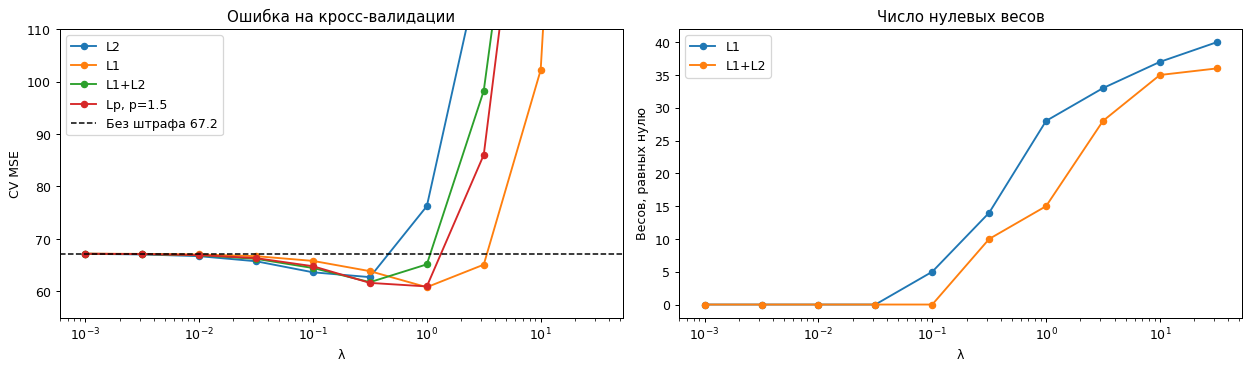

In [18]:
rng = np.random.default_rng(SEED)
sub = rng.choice(len(y_all), 600, replace=False)
X_reg, y_reg = X_simple[sub], y_all[sub]
lambdas = np.logspace(-3, 1.5, 10)
setups = {'L2': dict(penalty='l2'), 'L1': dict(penalty='l1'), 'L1+L2': dict(penalty='elasticnet', l1_ratio=.5), 'Lp, p=1.5': dict(penalty='lp', p=1.5)}
curves, zeros = {}, {}
for name, params in setups.items():
    scores, nulls = [], []
    for lam in lambdas:
        make = lambda: LinearRegression(method='gd', lam=lam, n_iter=1500, tol=1e-9, **params)
        oof, _ = cross_validate(make, X_reg, y_reg, kfold_splits(len(y_reg), 5))
        scores.append(mse(y_reg, oof))
        fitted_full = make().fit(ZScoreScaler().fit_transform(X_reg), y_reg)
        nulls.append(int((np.abs(fitted_full.coef_) < 1e-8).sum()))
    curves[name], zeros[name] = np.array(scores), nulls
baseline_oof, _ = cross_validate(make_ols, X_reg, y_reg, kfold_splits(len(y_reg), 5))
baseline_mse = mse(y_reg, baseline_oof)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name, values in curves.items():
    ax[0].plot(lambdas, values, marker='o', markersize=5, label=name)
ax[0].axhline(baseline_mse, color='black', linestyle='--', linewidth=1.2, label=f'Без штрафа {baseline_mse:.1f}')
ax[0].set(xscale='log', ylim=(55, 110), title='Ошибка на кросс-валидации', xlabel='λ', ylabel='CV MSE')
ax[0].legend()
for name in ['L1', 'L1+L2']:
    ax[1].plot(lambdas, zeros[name], marker='o', markersize=5, label=name)
ax[1].set(xscale='log', title='Число нулевых весов', xlabel='λ', ylabel='Весов, равных нулю')
ax[1].legend()
plt.tight_layout(); plt.show()

summary = pd.DataFrame({name: {'лучшее λ': lambdas[v.argmin()], 'лучший CV MSE': v.min()} for name, v in curves.items()}).T
print(summary.round(3).to_string())
print('Без штрафа:', round(baseline_mse, 3))
assert all(v.min() <= baseline_mse + 1e-6 for v in curves.values()), 'Подобранный штраф не должен быть хуже модели без штрафа'
assert zeros['L1'][-1] > zeros['L1'][0], 'С ростом λ L1 должен обнулять больше весов'
assert zeros['L2'][-1] == 0, 'L2 сжимает веса, но не обнуляет их'

- Реализации L1, L2 и L1+L2 совпали с `Lasso`, `Ridge` и `ElasticNet`, а Lp совпал с независимой численной минимизацией. При $p=2$ штраф Lp совпадает с L2
- L1 и L1+L2 обнуляют веса и поэтому могут работать как отбор признаков внутри самой линейной регрессии. L2 только сжимает веса
- Умеренный штраф улучшает качество при малом числе строк. Слишком большой $\lambda$ приводит к недообучению

## 8. Модель для Kaggle

### 8.1. Базовые модели

Для честного сравнения все модели оцениваются одной и той же кросс-валидацией, 5 фолдов и 3 разных разбиения. Всё, что считается по данным, обучается только внутри фолда

In [19]:
def derive_features(df):
    '''логарифмы признаков с тяжёлым хвостом, индикаторы границ и категории'''
    d = pd.DataFrame(index=df.index)
    for col in ['MonthlyIncome', 'TotalDebtToIncomeRatio', 'LoanAmount', 'MonthlyLoanPayment', 'MonthlyDebtPayments',
                'TotalAssets', 'NetWorth', 'BaseInterestRate', 'InterestRate']:
        d['log_' + col] = np.log(df[col].astype(float))
    for col in ['CreditScore', 'LengthOfCreditHistory', 'InterestRate', 'BaseInterestRate', 'NumberOfOpenCreditLines', 'Age', 'Experience',
                'DebtToIncomeRatio', 'CreditCardUtilizationRate']:
        d[col] = df[col].astype(float)
    d['Year'] = pd.to_datetime(df['ApplicationDate']).dt.year.astype(float)
    d['AgeCentered2'] = (df['Age'].astype(float) - 40) ** 2
    d['BankruptcyHistory'] = df['BankruptcyHistory'].astype(float)
    d['PreviousLoanDefaults'] = df['PreviousLoanDefaults'].astype(float)
    d['SelfEmployed'] = (df['EmploymentStatus'] == 'Self-Employed').astype(float)
    d['Unemployed'] = (df['EmploymentStatus'] == 'Unemployed').astype(float)
    for level in ['Bachelor', 'Doctorate', 'High School', 'Master']:
        d['Edu_' + level] = (df['EducationLevel'] == level).astype(float)
    d['PurposeDebt'] = (df['LoanPurpose'] == 'Debt Consolidation').astype(float)
    return d

FLAGS = ['BankruptcyHistory', 'PreviousLoanDefaults', 'SelfEmployed', 'Unemployed', 'Edu_Bachelor', 'Edu_Doctorate', 'Edu_High School', 'Edu_Master']
SPLINE_COLS = ['log_MonthlyIncome', 'CreditScore', 'log_TotalDebtToIncomeRatio', 'InterestRate', 'LengthOfCreditHistory', 'log_NetWorth',
               'log_TotalAssets', 'log_LoanAmount', 'BaseInterestRate', 'log_MonthlyDebtPayments', 'NumberOfOpenCreditLines', 'Year',
               'log_MonthlyLoanPayment', 'log_BaseInterestRate', 'log_InterestRate']


class SmoothFeatures:
    '''строит кубические сплайны. Параметры считаются только на train'''
    def __init__(self, n_spline_knots=5, extra_spline_cols=()):
        self.n_spline_knots = n_spline_knots
        self.spline_cols = SPLINE_COLS + list(extra_spline_cols)

    def fit(self, df):
        d = derive_features(df)
        cols = self.spline_cols
        self.low_, self.high_ = d[cols].min(), d[cols].max()
        self.mean_, self.std_ = d[cols].mean(), d[cols].std().replace(0, 1)
        z = (d[cols] - self.mean_) / self.std_
        grid = np.linspace(0, 1, self.n_spline_knots + 2)[1:-1]
        self.spline_knots_ = {c: np.unique(np.quantile(z[c], grid)) for c in cols}
        self.spline_scaler_ = ZScoreScaler().fit(self._raw(df))
        return self

    def _raw(self, df):
        d = derive_features(df)
        z = (d[self.spline_cols].clip(self.low_, self.high_, axis=1) - self.mean_) / self.std_
        parts = [d[FLAGS + ['PurposeDebt', 'AgeCentered2']].to_numpy()]
        for c in self.spline_cols:
            v = z[c].to_numpy()
            parts += [v[:, None], (v ** 2)[:, None], (v ** 3)[:, None]]
            parts += [(np.maximum(v - t, 0) ** 3)[:, None] for t in self.spline_knots_[c]]
        return np.column_stack(parts)

    def transform(self, df):
        return self.spline_scaler_.transform(self._raw(df))


def cv_frame(make_pipeline, df, y, seeds=(0, 1, 2), k=5):
    '''кросс-валидация для модели, которая сама строит признаки из таблицы'''
    rows, last_oof = [], None
    for seed in seeds:
        oof = np.full(len(y), np.nan)
        fold_scores = []
        for tr, val in kfold_splits(len(y), k, seed=seed):
            model = make_pipeline().fit(df.iloc[tr], y[tr])
            oof[val] = model.predict(df.iloc[val])
            fold_scores.append(mse(y[val], oof[val]))
        assert not np.isnan(oof).any()
        rows.append({**all_metrics(y, oof), 'std по фолдам': np.std(fold_scores)})
        last_oof = oof
    return pd.DataFrame(rows).mean(), last_oof


class RawOLS:
    '''МНК на сырых числовых признаках и one-hot категориях'''
    def _x(self, df):
        return pd.concat([df[num_cols].astype(float), one_hot(df)], axis=1).to_numpy()
    def fit(self, df, y):
        self.scaler_ = ZScoreScaler()
        self.model_ = LinearRegression(method='analytic').fit(self.scaler_.fit_transform(self._x(df)), y)
        return self
    def predict(self, df):
        return self.model_.predict(self.scaler_.transform(self._x(df)))


ADDITIVE_EXTRA = ['DebtToIncomeRatio', 'CreditCardUtilizationRate']


class AdditiveSplineRidge:
    '''гребневая регрессия на сплайнах от преобразованных признаков'''
    def fit(self, df, y):
        self.features_ = SmoothFeatures(extra_spline_cols=ADDITIVE_EXTRA).fit(df)
        spline = self.features_.transform(df)
        self.model_ = LinearRegression(method='analytic', penalty='l2', lam=1 / len(y)).fit(spline, y)
        return self
    def predict(self, df):
        return self.model_.predict(self.features_.transform(df))


results = {}
results['МНК на сырых признаках'], raw_oof = cv_frame(RawOLS, train, y_all)
results['Ridge на сплайнах'], spline_oof = cv_frame(AdditiveSplineRidge, train, y_all)
print(pd.DataFrame(results).T.round(4).to_string())

                            MSE     MAE      R2    MAPE  std по фолдам
МНК на сырых признаках  50.7620  5.7207  0.8293  0.1343         1.5384
Ridge на сплайнах       25.5931  3.8229  0.9139  0.0896         0.6180


### 8.2. Откуда берётся ошибка. Анализ остатков

Сплайны улучшают результат, но порог не проходят. Если остатки распределены бимодально, то ошибка связана не с формой зависимости, а со скрытым фактором. Модель с индикатором полосы $b \in \{0, 1\}$ можно обучить, чередуя обычные линейные регрессии:

1. Обучить МНК на $y = f(x) + \delta b$ при текущих метках $b$
2. Присвоить каждой строке ту полосу, прогноз которой ближе к $y$
3. Повторять, пока метки меняются

Сдвиг между полосами: 15.53 | доля верхней полосы: 0.489 | MSE при известной полосе: 8.673


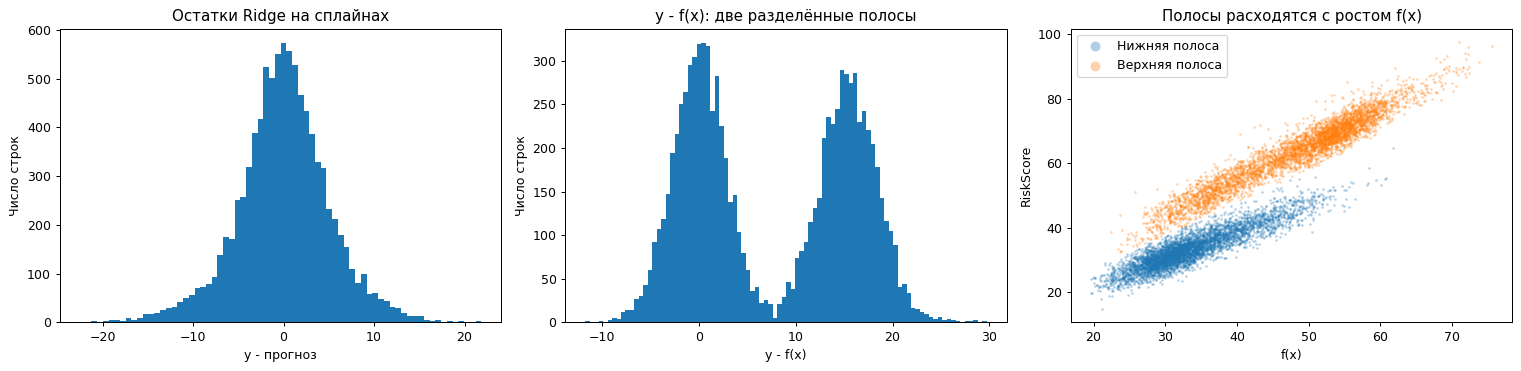

In [20]:
def initial_band_labels(df, y, max_iter=20):
    features = SmoothFeatures(extra_spline_cols=ADDITIVE_EXTRA).fit(df)
    spline = features.transform(df)
    b = (y > np.median(y)).astype(float)
    for _ in range(max_iter):
        model = LinearRegression(method='analytic', penalty='l2', lam=1 / len(y)).fit(np.column_stack([spline, b]), y)
        delta = model.coef_[-1]
        f = spline @ model.coef_[:-1] + model.intercept_
        new_b = ((y - f) > delta / 2).astype(float)
        if (new_b == b).all():
            break
        b = new_b
    return b, f, delta

band0, f0, delta0 = initial_band_labels(train, y_all)
print(f'Сдвиг между полосами: {delta0:.2f} | доля верхней полосы: {band0.mean():.3f} | MSE при известной полосе: {mse(y_all, f0 + delta0 * band0):.3f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(y_all - spline_oof, bins=70)
ax[0].set(title='Остатки Ridge на сплайнах', xlabel='y - прогноз', ylabel='Число строк')
ax[1].hist(y_all - f0, bins=90)
ax[1].set(title='y - f(x): две разделённые полосы', xlabel='y - f(x)', ylabel='Число строк')
for value, label in [(0, 'Нижняя полоса'), (1, 'Верхняя полоса')]:
    mask = band0 == value
    ax[2].scatter(f0[mask], y_all[mask], s=4, alpha=.35, linewidths=0, label=label)
ax[2].set(title='Полосы расходятся с ростом f(x)', xlabel='f(x)', ylabel='RiskScore')
ax[2].legend(markerscale=4)
plt.tight_layout(); plt.show()

Остатки действительно состоят из двух разделённых полос, причём расстояние между ними растёт с ростом прогноза. Полосы отличаются не сдвигом, а множителем

### 8.3. Отбор признаков, ступени на круглых значениях

Внутри полосы зависимость выглядит не гладкой, а ступенчатой. Чтобы проверить это, строится прямой отбор пороговых индикаторов `признак >= t` на сетке округлых значений. Критерий это снижение MSE обычной линейной регрессии на 5-fold внутри 70% данных. Оставшиеся 30% не участвуют в отборе и служат контролем

In [21]:
THRESHOLD_GRID = {
    'CreditScore': np.arange(325, 850, 25), 'AnnualIncome': [20e3, 25e3, 30e3, 35e3, 40e3, 50e3, 60e3, 70e3, 75e3, 80e3, 90e3, 100e3, 120e3, 125e3, 150e3, 175e3, 200e3, 250e3],
    'DebtToIncomeRatio': np.arange(.05, .8, .05).round(2), 'CreditCardUtilizationRate': np.arange(.05, .85, .05).round(2),
    'LengthOfCreditHistory': np.arange(2, 30), 'NetWorth': [2e3, 5e3, 10e3, 20e3, 25e3, 30e3, 40e3, 50e3, 75e3, 100e3, 150e3, 200e3, 250e3, 300e3, 400e3, 500e3, 750e3, 1e6, 1.5e6, 2e6, 3e6, 5e6],
    'TotalAssets': [10e3, 25e3, 50e3, 100e3, 200e3, 250e3, 500e3, 1e6, 2e6], 'TotalLiabilities': [10e3, 25e3, 50e3, 100e3, 250e3, 500e3, 1e6],
    'LoanAmount': [5e3, 10e3, 20e3, 30e3, 50e3, 100e3], 'LoanDuration': [24, 36, 48, 60, 72, 84, 96, 108],
    'TotalDebtToIncomeRatio': [.1, .2, .3, .4, .5, .75, 1, 2], 'PaymentHistory': np.arange(14, 38, 2), 'UtilityBillsPaymentHistory': np.arange(.4, 1, .1).round(1),
    'Age': [25, 30, 40, 50, 60, 70], 'JobTenure': [2, 4, 6, 8, 10], 'NumberOfOpenCreditLines': [1, 2, 4, 6, 8], 'NumberOfCreditInquiries': [1, 2, 3],
}
pool = {f'{col}>={t:g}': (train[col].to_numpy() >= t).astype(float) for col, grid in THRESHOLD_GRID.items() for t in grid}
pool.update({'BankruptcyHistory': train['BankruptcyHistory'].to_numpy(float), 'PreviousLoanDefaults': train['PreviousLoanDefaults'].to_numpy(float),
             'Employed': (train['EmploymentStatus'] == 'Employed').to_numpy(float), 'Master+': train['EducationLevel'].isin(['Master', 'Doctorate']).to_numpy(float)})
pool_names = [k for k, v in pool.items() if v.std() > 0]
pool_matrix = np.column_stack([pool[k] for k in pool_names])
pool_z = ZScoreScaler().fit_transform(pool_matrix)

dev, hold = split_indices(len(y_all), test_size=.3, seed=123)
sel_folds = list(kfold_splits(len(dev), 5, seed=5))
b_c = band0 - .5

def selection_cv(columns):
    A = np.column_stack([b_c] + [pool_z[:, j] for j in columns])[dev]
    y_dev, oof = y_all[dev], np.zeros(len(dev))
    for tr, val in sel_folds:
        oof[val] = LinearRegression(method='analytic').fit(A[tr], y_dev[tr]).predict(A[val])
    return mse(y_dev, oof), y_dev - oof

def holdout_score(columns):
    A = np.column_stack([b_c] + [pool_z[:, j] for j in columns])
    return mse(y_all[hold], LinearRegression(method='analytic').fit(A[dev], y_all[dev]).predict(A[hold]))

selected, trace = [], []
score, residual = selection_cv(selected)
for step in range(60):
    candidates = np.argsort(-np.abs(pool_z[dev].T @ residual))
    candidates = [j for j in candidates if j not in selected][:6]
    best = min(((selection_cv(selected + [j])[0], j) for j in candidates), key=lambda item: item[0])
    if best[0] >= score - 1e-2:
        break
    selected.append(best[1])
    score, residual = selection_cv(selected)
    trace.append({'шаг': step + 1, 'признак': pool_names[best[1]], 'CV MSE': score, 'MSE на контроле': holdout_score(selected)})
trace = pd.DataFrame(trace)
print(trace.iloc[list(range(0, len(trace), 5)) + [len(trace) - 1]].round(3).to_string(index=False))
print('\nОтобранные пороги, сгруппированные по признакам:')
print(pd.Series(sorted(pool_names[j] for j in selected)).to_string(index=False))

 шаг                признак  CV MSE  MSE на контроле
   1       CreditScore>=650  38.109           40.282
   6       CreditScore>=750  17.014           17.219
  11 DebtToIncomeRatio>=0.4  12.358           12.893
  16   PreviousLoanDefaults   9.617           10.487
  21 DebtToIncomeRatio>=0.5   8.124            9.023
  26        NetWorth>=1e+06   7.860            8.600
  30   AnnualIncome>=250000   7.775            8.518

Отобранные пороги, сгруппированные по признакам:
          AnnualIncome>=120000
          AnnualIncome>=250000
           AnnualIncome>=30000
           AnnualIncome>=50000
           AnnualIncome>=80000
             BankruptcyHistory
CreditCardUtilizationRate>=0.2
CreditCardUtilizationRate>=0.4
CreditCardUtilizationRate>=0.6
              CreditScore>=600
              CreditScore>=650
              CreditScore>=700
              CreditScore>=750
        DebtToIncomeRatio>=0.2
        DebtToIncomeRatio>=0.3
        DebtToIncomeRatio>=0.4
        DebtToIncomeRatio>=0.5

Отбор находит ступени на круглых значениях, а MSE на контроле снижается вместе с MSE на кросс-валидации, поэтому это реальная структура данных, а не переобучение

Из 30 отобранных признаков 27 образуют регулярную скоринговую карту, она зафиксирована ниже. Три оставшихся порога (`AnnualIncome>=250000`, `NetWorth>=300000`, `TotalDebtToIncomeRatio>=0.5`) в карту не вошли

In [22]:
SCORECARD = {
    'AnnualIncome': [30000, 50000, 80000, 120000],
    'CreditCardUtilizationRate': [.2, .4, .6],
    'CreditScore': [600, 650, 700, 750],
    'DebtToIncomeRatio': [.2, .3, .4, .5],
    'LengthOfCreditHistory': [3, 5, 7, 10],
    'NetWorth': [50000, 100000, 250000, 500000, 1000000],
}

def scorecard_features(df):
    '''индикаторы порогов скоринговой карты и три бинарных признака'''
    columns = {f'{col}>={t:g}': (df[col].to_numpy(float) >= t).astype(float) for col, grid in SCORECARD.items() for t in grid}
    columns['BankruptcyHistory'] = df['BankruptcyHistory'].to_numpy(float)
    columns['PreviousLoanDefaults'] = df['PreviousLoanDefaults'].to_numpy(float)
    columns['Employed'] = (df['EmploymentStatus'] == 'Employed').to_numpy(float)
    return pd.DataFrame(columns, index=df.index)

BAND_COLUMNS = ['CreditScore', 'MonthlyIncome', 'TotalDebtToIncomeRatio', 'LoanAmount', 'InterestRate', 'BankruptcyHistory', 'PreviousLoanDefaults',
                'PaymentHistory', 'LengthOfCreditHistory', 'NetWorth', 'Age', 'Experience']

def band_features(df, age_knots=(30, 40, 50, 60)):
    '''столбцы данных, категории и изломы возраста для индекса полосы'''
    d = df[BAND_COLUMNS].astype(float).copy()
    d['Unemployed'] = (df['EmploymentStatus'] == 'Unemployed').astype(float)
    d['OwnOrMortgage'] = df['HomeOwnershipStatus'].isin(['Own', 'Mortgage']).astype(float)
    for level in ['Associate', 'Bachelor', 'Master', 'Doctorate']:
        d['Education=' + level] = (df['EducationLevel'] == level).astype(float)
    for knot in age_knots:
        d[f'Age>{knot}'] = np.maximum(df['Age'].astype(float) - knot, 0)
    return d


class ScorecardMixtureRegression:
    '''
    прогноз E[y | x] = S(x) · (1 + κ · P(x)).
    S(x) это линейная скоринговая карта, κ это множитель верхней полосы, P(x) это линейный индекс, обрезанный до [0, 1]
    '''
    def __init__(self, soft=True, near_iters=4, age_knots=(30, 40, 50, 60), kappa0=.36, max_em_iter=25, lam_index=1e-3):
        self.soft, self.near_iters, self.age_knots = soft, near_iters, age_knots
        self.kappa0, self.max_em_iter, self.lam_index = kappa0, max_em_iter, lam_index

    def _fit_score(self, A, y):
        kappa, labels = self.kappa0, None
        ols = LinearRegression(method='analytic', fit_intercept=False)
        w = ols.fit(A, y / (1 + kappa * (y > np.median(y)))).coef_
        for _ in range(self.max_em_iter):
            S = A @ w
            new_labels = (np.abs(y - S * (1 + kappa)) < np.abs(y - S)).astype(float)
            if labels is not None and (new_labels == labels).all():
                break
            labels = new_labels
            for _ in range(3):
                w = ols.fit(A * (1 + kappa * labels)[:, None], y).coef_
                S = A @ w
                kappa = LinearRegression(method='analytic', fit_intercept=False).fit((labels * S)[:, None], y - S).coef_[0]
        return w, kappa, labels

    def _fit_index(self, X, r):
        '''МНК по вероятностям полосы, дообученный на строках рядом с границей'''
        fit = lambda X_part, r_part: LinearRegression(method='analytic', penalty='l2', lam=self.lam_index).fit(X_part, r_part)
        model = fit(X, r)
        for _ in range(self.near_iters):
            u = model.predict(X)
            near = (u > .1) & (u < .9)
            model = fit(X[near], r[near])
        return model

    def _fit_score_soft(self, A, y, X, w, kappa, labels, n_rounds=4, n_steps=10):
        '''
        EM вместо жёстких меток, r это вероятность верхней полосы при известном y.
        Каждая строка входит в МНК дважды, с весами r и 1 - r. Априорная вероятность полосы берётся из индекса
        '''
        ols = LinearRegression(method='analytic', fit_intercept=False)
        sigma2 = np.mean((y - (A @ w) * (1 + kappa * labels)) ** 2)
        prior = np.full(len(y), .5)
        for _ in range(n_rounds):
            for _ in range(n_steps):
                S = A @ w
                log_ratio = (((y - S) ** 2 - (y - S * (1 + kappa)) ** 2) / (2 * sigma2))
                r = prior / (prior + (1 - prior) * np.exp(-np.clip(log_ratio, -500, 500)))
                root_r, root_q = np.sqrt(r)[:, None], np.sqrt(1 - r)[:, None]
                design = np.vstack([A * (1 + kappa) * root_r, A * root_q])
                target = np.concatenate([y * root_r[:, 0], y * root_q[:, 0]])
                w = ols.fit(design, target).coef_
                S = A @ w
                kappa = np.sum(r * S * (y - S)) / np.sum(r * S * S)
                sigma2 = np.mean(r * (y - S * (1 + kappa)) ** 2 + (1 - r) * (y - S) ** 2)
            prior = np.clip(self._fit_index(X, r).predict(X), 1e-3, 1 - 1e-3)
        return w, kappa, r

    def fit(self, df, y):
        y = np.asarray(y, float)
        A = np.column_stack([np.ones(len(y)), scorecard_features(df).to_numpy()])
        self.band_scaler_ = ZScoreScaler()
        X = self.band_scaler_.fit_transform(band_features(df, self.age_knots).to_numpy())
        self.w_, self.kappa_, self.labels_ = self._fit_score(A, y)
        self.responsibilities_ = self.labels_
        if self.soft:
            self.w_, self.kappa_, self.responsibilities_ = self._fit_score_soft(A, y, X, self.w_, self.kappa_, self.labels_)
            self.labels_ = (self.responsibilities_ > .5).astype(float)
        self.index_ = self._fit_index(X, self.responsibilities_)
        return self

    def band_index(self, df):
        return self.index_.predict(self.band_scaler_.transform(band_features(df, self.age_knots).to_numpy()))

    def score(self, df):
        return np.column_stack([np.ones(len(df)), scorecard_features(df).to_numpy()]) @ self.w_

    def band_probability(self, df):
        return np.clip(self.band_index(df), 0, 1)

    def predict(self, df):
        return self.score(df) * (1 + self.kappa_ * self.band_probability(df))


probe = ScorecardMixtureRegression().fit(train, y_all)
scorecard_table = pd.Series(probe.w_, index=['Константа'] + list(scorecard_features(train).columns)).round(2)
print(f'κ = {probe.kappa_:.3f} | доля верхней полосы = {probe.labels_.mean():.3f}')
print(f'MSE при известной полосе на обучении: {mse(y_all, probe.score(train) * (1 + probe.kappa_ * probe.labels_)):.3f}')
print('\nВеса скоринговой карты S(x):')
print(scorecard_table.to_string())

hold_model = ScorecardMixtureRegression().fit(train.iloc[dev], y_all[dev])
S_hold = hold_model.score(train.iloc[hold])
hold_labels = (np.abs(y_all[hold] - S_hold * (1 + hold_model.kappa_)) < np.abs(y_all[hold] - S_hold)).astype(float)
hold_card_mse = mse(y_all[hold], S_hold * (1 + hold_model.kappa_ * hold_labels))
print(f'\nMSE карты внутри полосы на контроле: {hold_card_mse:.3f}')
assert hold_card_mse < 7.5, 'Карта должна подтверждаться на отложенных данных'

κ = 0.418 | доля верхней полосы = 0.488
MSE при известной полосе на обучении: 6.496

Веса скоринговой карты S(x):
Константа                         52.54
AnnualIncome>=30000               -1.61
AnnualIncome>=50000               -1.85
AnnualIncome>=80000               -1.69
AnnualIncome>=120000              -1.89
CreditCardUtilizationRate>=0.2     0.98
CreditCardUtilizationRate>=0.4     0.97
CreditCardUtilizationRate>=0.6     0.77
CreditScore>=600                  -2.95
CreditScore>=650                  -2.91
CreditScore>=700                  -2.83
CreditScore>=750                  -3.02
DebtToIncomeRatio>=0.2             1.60
DebtToIncomeRatio>=0.3             1.47
DebtToIncomeRatio>=0.4             1.53
DebtToIncomeRatio>=0.5             1.75
LengthOfCreditHistory>=3          -0.95
LengthOfCreditHistory>=5          -0.61
LengthOfCreditHistory>=7          -0.86
LengthOfCreditHistory>=10         -0.72
NetWorth>=50000                   -1.56
NetWorth>=100000                  -1.50
NetWor

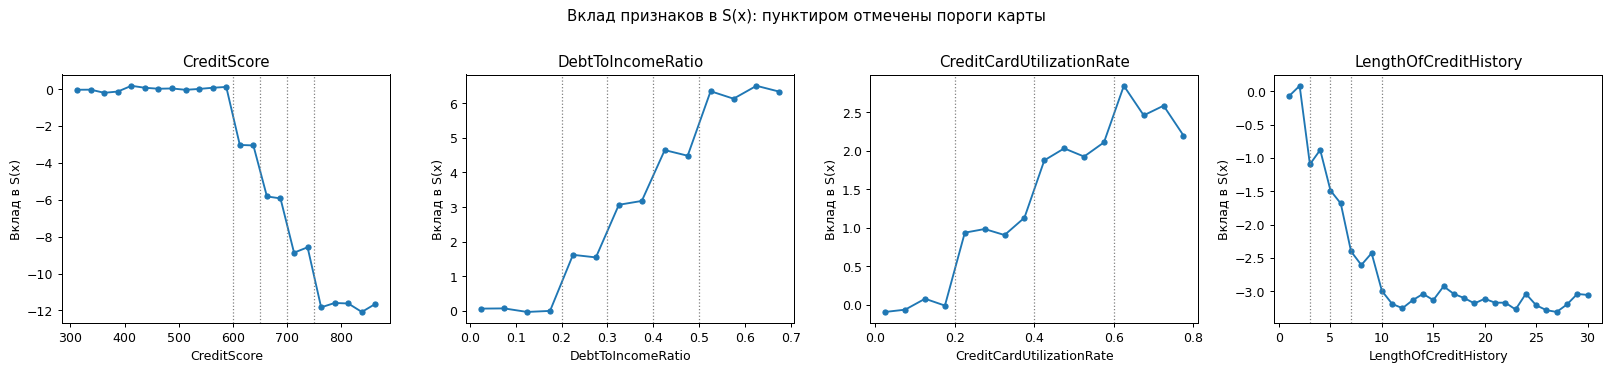

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
y_debanded = y_all / (1 + probe.kappa_ * probe.labels_)
card = scorecard_features(train).to_numpy()
card_names = list(scorecard_features(train).columns)
weights = probe.w_[1:]
for a, (col, grid) in zip(ax, [('CreditScore', np.arange(300, 876, 25)), ('DebtToIncomeRatio', np.arange(0, .71, .05)),
                               ('CreditCardUtilizationRate', np.arange(0, .81, .05)), ('LengthOfCreditHistory', np.arange(.5, 31, 1))]):
    own = np.array([name.startswith(col + '>=') for name in card_names])
    partial = y_debanded - (probe.w_[0] + card[:, ~own] @ weights[~own])
    bins = pd.cut(train[col], grid, right=False)
    profile = pd.Series(partial).groupby(bins.to_numpy()).mean()
    a.plot([iv.mid for iv in profile.index], profile.values, marker='o', markersize=4)
    for t in SCORECARD[col]:
        a.axvline(t, color='gray', linestyle=':', linewidth=1)
    a.set(title=col, xlabel=col, ylabel='Вклад в S(x)')
fig.suptitle('Вклад признаков в S(x): пунктиром отмечены пороги карты', y=1.02)
plt.tight_layout(); plt.show()

### 8.4. Итоговая модель

$$\hat y(x) = S(x)\,\bigl(1 + \kappa\,P(x)\bigr),\qquad P(x) = \mathrm{clip}\bigl(w_0 + w^\top g(x),\ 0,\ 1\bigr)$$

Этапы (каждый это обычная линейная регрессия из класса `LinearRegression`):

1. Скоринговая карта $S(x)$. МНК на 27 пороговых индикаторах. Веса карты, множитель $\kappa$ и вероятности полос $r$ уточняются поочерёдно (EM). Каждая строка входит в МНК дважды, с весами $r$ и $1-r$. Так строки, близкие к середине между полосами, не получают ошибочную жёсткую метку
2. Вероятность полосы $P(x)$. Это линейная регрессия вероятностей $r$ на признаки $g(x)$ с прогнозом, обрезанным до отрезка $[0, 1]$. После первого обучения МНК четыре раза повторяется только на строках, где прогноз попал в интервал от 0.1 до 0.9
3. Прогноз это математическое ожидание $y$ при неизвестной полосе

Обучение рядом с границей нужно потому, что строки с прогнозом за пределами отрезка всё равно будут обрезаны. Обычный МНК по всем строкам тратит веса на эти строки и на выбросы вроде очень большого `TotalDebtToIncomeRatio`, что видно по таблице ниже

Признаки $g(x)$ это столбцы данных, три категориальных признака и изломы возраста в 30, 40, 50 и 60 лет

                                                 MSE     MAE      R2    MAPE  std по фолдам
МНК на сырых признаках                       50.7620  5.7207  0.8293  0.1343         1.5384
Ridge на сплайнах                            25.5931  3.8229  0.9139  0.0896         0.6180
Скоринговая карта без полос                  30.5672  4.0430  0.8972  0.0947         1.3146
S(x)(1 + κP(x)), жёсткие метки               18.2571  2.9698  0.9386  0.0687         0.7123
S(x)(1 + κP(x)), индекс МНК по всем строкам  27.3740  4.0526  0.9079  0.0944         0.7927
S(x)(1 + κP(x)), без изломов возраста        18.3704  2.9699  0.9382  0.0688         0.7561
Итоговая модель S(x)(1 + κP(x))              18.2221  2.9606  0.9387  0.0686         0.7054


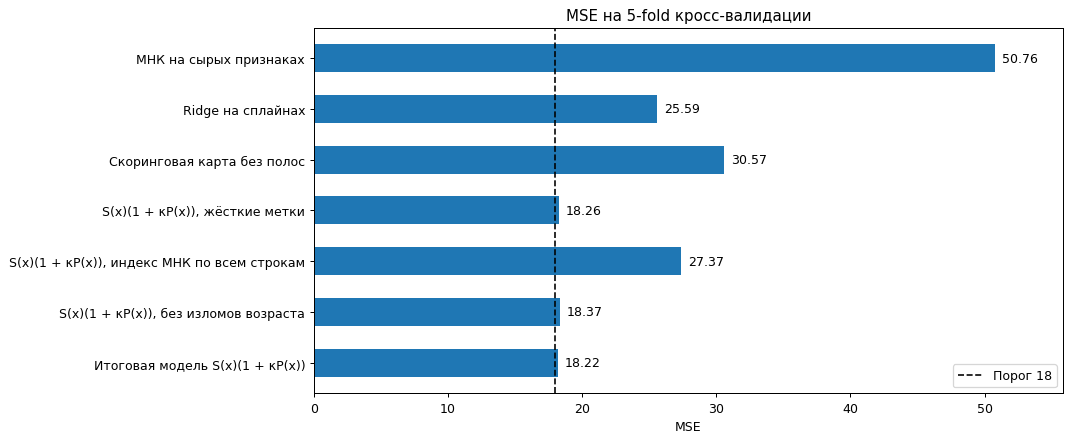

In [24]:
class LinearScorecard:
    '''МНК только на индикаторах скоринговой карты, без учёта скрытых полос'''
    def fit(self, df, y):
        self.model_ = LinearRegression(method='analytic').fit(scorecard_features(df).to_numpy(), y)
        return self
    def predict(self, df):
        return self.model_.predict(scorecard_features(df).to_numpy())

results['Скоринговая карта без полос'], _ = cv_frame(LinearScorecard, train, y_all)
results['S(x)(1 + κP(x)), жёсткие метки'], _ = cv_frame(lambda: ScorecardMixtureRegression(soft=False), train, y_all)
results['S(x)(1 + κP(x)), индекс МНК по всем строкам'], _ = cv_frame(lambda: ScorecardMixtureRegression(near_iters=0), train, y_all)
results['S(x)(1 + κP(x)), без изломов возраста'], _ = cv_frame(lambda: ScorecardMixtureRegression(age_knots=()), train, y_all)
results['Итоговая модель S(x)(1 + κP(x))'], final_oof = cv_frame(ScorecardMixtureRegression, train, y_all)
table = pd.DataFrame(results).T
print(table.round(4).to_string())

labels = list(table.index)[::-1]
values = table['MSE'].to_numpy()[::-1]
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(labels, values, height=.55)
for i, v in enumerate(values):
    ax.text(v + .5, i, f'{v:.2f}', va='center', color='black')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=1.3, label=f'Порог {THRESHOLD:.0f}')
ax.set(title='MSE на 5-fold кросс-валидации', xlabel='MSE', xlim=(0, values.max() * 1.1))
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

assert table.loc['Итоговая модель S(x)(1 + κP(x))', 'MSE'] < table['MSE'].drop('Итоговая модель S(x)(1 + κP(x))').min(), 'Итоговая модель должна быть лучше базовых'

In [25]:
hold_metrics = all_metrics(y_all[hold], hold_model.predict(train.iloc[hold]))
print(f'Контроль, итоговая модель: MSE {hold_metrics["MSE"]:.3f}, MAE {hold_metrics["MAE"]:.3f}, R2 {hold_metrics["R2"]:.4f}, MAPE {hold_metrics["MAPE"]:.4f}')

Контроль, итоговая модель: MSE 18.043, MAE 2.978, R2 0.9414, MAPE 0.0687


### Проверка индекса на данных

Индекс должен быть откалиброван вне обучения, а его веса должны объясняться данными

In [26]:
band_names = list(band_features(train).columns)
scale = probe.band_scaler_.scale_
index_table = pd.DataFrame({'вес на единицу признака': probe.index_.coef_ / scale, 'вес на одно σ': probe.index_.coef_}, index=band_names)
print(index_table.reindex(index_table['вес на одно σ'].abs().sort_values(ascending=False).index).to_string(float_format=lambda v: f'{v:.3g}'))

share_by_score = pd.Series(probe.labels_).groupby(pd.cut(train['CreditScore'], [299, 600, 700, 800, 851]), observed=True).mean()
print('\nДоля верхней полосы по CreditScore:', share_by_score.round(3).to_dict())
direct = index_table.loc['CreditScore', 'вес на единицу признака']
through_rate = index_table.loc['InterestRate', 'вес на единицу признака'] * -.0005
print(f'Вес CreditScore: прямой {direct:.5f}, через InterestRate {through_rate:.5f}, вместе {direct + through_rate:.5f}')

oof_index = np.zeros(len(y_all))
oof_labels = np.zeros(len(y_all))
for tr, val in kfold_splits(len(y_all), 5, seed=0):
    model = ScorecardMixtureRegression().fit(train.iloc[tr], y_all[tr])
    oof_index[val] = model.band_probability(train.iloc[val])
    S_val = model.score(train.iloc[val])
    oof_labels[val] = np.abs(y_all[val] - S_val * (1 + model.kappa_)) < np.abs(y_all[val] - S_val)
calibration = pd.DataFrame({'P': oof_index, 'b': oof_labels}).groupby(pd.cut(oof_index, [-.01, .1, .3, .5, .7, .9, 1]), observed=True).agg(P=('P', 'mean'), b=('b', 'mean'), n=('b', 'size'))
print('\nКалибровка P(x) вне обучения:')
print(calibration.round(3).to_string())
assert (calibration['P'] - calibration['b']).abs().max() < .15, 'P(x) плохо откалибрована'

                        вес на единицу признака  вес на одно σ
TotalDebtToIncomeRatio                     1.26           1.07
MonthlyIncome                         -7.57e-05          -0.71
InterestRate                               6.55           0.63
NetWorth                              -1.29e-06         -0.586
CreditScore                             0.00253          0.443
LoanAmount                             6.81e-06          0.186
Age>50                                   0.0294          0.105
LengthOfCreditHistory                   -0.0102        -0.0881
BankruptcyHistory                          0.36         0.0801
Education=Bachelor                       -0.152        -0.0692
Age>30                                  0.00679         0.0671
Age                                    -0.00562        -0.0651
Experience                             -0.00506        -0.0573
Education=Doctorate                      -0.314        -0.0562
PreviousLoanDefaults                      0.147        

Выводы проверки:

- Знаки весов согласуются с данными. Верхняя полоса вероятнее при большем `TotalDebtToIncomeRatio` и `InterestRate` и при меньших доходе и `NetWorth`
- Прямой вес `CreditScore` положительный, но `InterestRate` сам снижается на 0.0005 с каждым баллом рейтинга. Вместе вес равен −0.00075, поэтому доля верхней полосы с ростом рейтинга падает
- $P(x)$ откалибрована вне обучения. В каждой группе предсказанная вероятность отличается от доли верхней полосы не больше чем на 0.02

### 8.5. Финальное обучение и файл посылки

Прогноз на test: среднее 48.17, min 21.58, max 93.54
Прогноз вне обучения на train: среднее 48.31, min 21.54, max 95.28
Файл сохранён: submission.csv
 ID  RiskScore
  0  32.925334
  1  53.425524
  2  30.019134
  3  34.912057
  4  33.018581


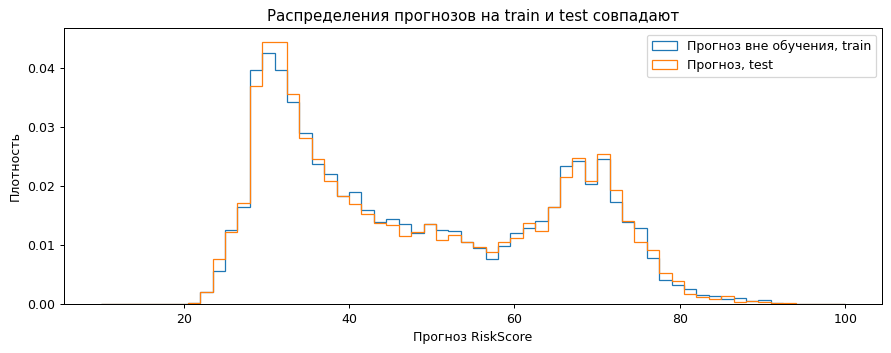

In [27]:
final_model = ScorecardMixtureRegression().fit(train, y_all)
test_pred = final_model.predict(test)

submission = pd.DataFrame({'ID': test['ID'], TARGET: test_pred})
submission.to_csv(OUT / 'submission.csv', index=False)

saved = pd.read_csv(OUT / 'submission.csv')
assert list(saved.columns) == list(sample.columns), 'Столбцы должны совпадать с примером посылки'
assert saved['ID'].equals(sample['ID']), 'ID должны совпадать с примером посылки'
assert saved.shape == sample.shape and saved[TARGET].notna().all() and np.isfinite(saved[TARGET]).all()

print(f'Прогноз на test: среднее {saved[TARGET].mean():.2f}, min {saved[TARGET].min():.2f}, max {saved[TARGET].max():.2f}')
print(f'Прогноз вне обучения на train: среднее {final_oof.mean():.2f}, min {final_oof.min():.2f}, max {final_oof.max():.2f}')

fig, ax = plt.subplots(figsize=(10, 4))
grid = np.linspace(10, 100, 61)
ax.hist(final_oof, bins=grid, density=True, histtype='step', label='Прогноз вне обучения, train')
ax.hist(test_pred, bins=grid, density=True, histtype='step', label='Прогноз, test')
ax.set(title='Распределения прогнозов на train и test совпадают', xlabel='Прогноз RiskScore', ylabel='Плотность')
ax.legend()
plt.tight_layout(); plt.show()
print('Файл сохранён:', OUT / 'submission.csv')
print(saved.head().to_string(index=False))

## Итог

Устройство данных, найденное анализом остатков:

$$y = S(x)\,(1 + 0,4\,b) + \varepsilon,\qquad \mathrm{Var}(\varepsilon) \approx 6,3$$

- $S(x)$ это скоринговая карта с порогами на круглых значениях, `CreditScore` 600, 650, 700, 750; `DebtToIncomeRatio` 0,2, 0,3, 0,4, 0,5; и другие
- $b$ это скрытый бинарный фактор, которого нет среди признаков. Верхняя полоса примерно в 1,4 раза выше нижней
- Вероятность $b=1$ оценивается линейным индексом по столбцам данных, обрезанным до отрезка $[0, 1]$. Веса индекса обучаются на итоговой ошибке прогноза